# Nástroje a knihovny pro zpracování obrazu v Pythonu

## Poznámka pro uživatele Matlabu

Pokud jste doteď pracovali převážně s Matlabem, většina konceptů vám bude povědomá - pole, indexování, vektorizace, zobrazování obrázků. Je ale pár rozdílů, na které je dobré si dát pozor a na které budeme v notebooku postupně upozorňovat:

- **Indexování od nuly.** Python (a NumPy) indexuje od 0, ne od 1, a u výřezů (`slice`) je horní mez *nezahrnuta* (`a[0:2]` vrátí prvky na indexech 0 a 1, zatímco `a(1:2)` v Matlabu vrátí prvky 1 a 2).
- **Jupyter notebook ≈ Live Script.** Buňky se spouštějí jednotlivě, výstup poslední buňky se zobrazí automaticky - pokud řádek nezakončíte středníkem `;`, stejně jako v Matlabu.
- **Nápověda.** Místo `help` nebo `doc` v Matlabu použijte v Jupyteru `?np.sum`, `np.sum?`, `help(np.sum)`, nebo klávesu Tab pro doplňování a nabídku parametrů.

# Poznámka na okraj: Markdown

- Markdown je jednoduchý značkovací jazyk pro vytváření formátovaného textu v obyčejném textovém editoru.

<figure class="image">
  <img src="../figures/markdown_logo.svg" alt="" style="height: 1.6in"/>
</figure>

https://www.markdownguide.org/

- Můžeme použít různé styly písma, např.

  Běžný text, dále **tučně**, *kurzívou*, ***tučně a kurzívou***
- Můžeme také psát matematiku, např.

  $$\frac{a^2}{(\log \sqrt p)}$$

- Odkaz na kód může vypadat třeba takto: `this_is_name_of_variable`
- Markdown podporuje zvýrazňování syntaxe pro různé jazyky, např.
  Python
  ``` python
  class A:
      pass
  ```
  nebo Javascript
  ``` javascript
  let x = Math.Random()
  ```
  i samotný Markdown
  ``` markdown
  regular, **bold**, *italic*, ...
  ```

# Numpy

- NumPy je knihovna s podporou velkých, vícerozměrných polí (array) a matic, společně s rozsáhlou sbírkou matematických funkcí vysoké úrovně pro práci s těmito poli.
- Pro uživatele Matlabu: `numpy.ndarray` je obdobou Matlabovského pole/matice. Na rozdíl od Matlabu ale NumPy nerozlišuje mezi „maticí“ a „polem“ - vše je `ndarray` libovolné dimenze (1D, 2D, 3D, ...).

<figure class="image">
  <img src="../figures/numpy_logo.svg" alt="" style="height: 1.6in"/>
</figure>

https://numpy.org/

In [1]:
import numpy as np

In [2]:
np.arange(12)

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])

In [3]:
m = np.arange(12).reshape(3, 4)
m

array([[ 0,  1,  2,  3],
       [ 4,  5,  6,  7],
       [ 8,  9, 10, 11]])

In [4]:
type(m), m.shape, m.dtype

(numpy.ndarray, (3, 4), dtype('int64'))

In [5]:
type(m.shape)

tuple

In [6]:
m[1, 2]

np.int64(6)

In [7]:
m.T

array([[ 0,  4,  8],
       [ 1,  5,  9],
       [ 2,  6, 10],
       [ 3,  7, 11]])

## Indexování

Stejně jako v Matlabu můžeme pole indexovat pomocí hranatých závorek a dvojtečky `:` pro výběr celé dimenze. Hlavní rozdíly oproti Matlabu:

- indexování začíná od **0**, ne od 1,
- u výřezu `start:stop` je `stop` **nezahrnuto** (např. `m[:2, :]` vrátí řádky s indexy 0 a 1, ne řádky 1 a 2 jako v Matlabu `m(1:2, :)`),
- záporné indexy počítají od konce (`m[-1]` je poslední řádek, `m[-2]` předposlední).

In [8]:
m

array([[ 0,  1,  2,  3],
       [ 4,  5,  6,  7],
       [ 8,  9, 10, 11]])

In [9]:
r = m[0, :]
r

array([0, 1, 2, 3])

In [10]:
r.shape

(4,)

**Pozor:** výběrem jednoho řádku `m[0, :]` dostaneme **1D pole** tvaru `(4,)`, ne řádkový vektor `1×4` jako v Matlabu. NumPy nerozlišuje řádkové a sloupcové vektory - 1D pole nemá orientaci. Pokud potřebujeme skutečně 2D tvar `(1, 4)`, použijeme např. `m[0:1, :]` nebo `m[0, :].reshape(1, -1)`.

In [11]:
type(r.shape), len(r.shape)

(tuple, 1)

In [12]:
m[0]

array([0, 1, 2, 3])

In [13]:
m[:, 1]

array([1, 5, 9])

In [14]:
m[:, 1].shape

(3,)

In [15]:
m[:, 1:]

array([[ 1,  2,  3],
       [ 5,  6,  7],
       [ 9, 10, 11]])

In [16]:
m[:2, :]

array([[0, 1, 2, 3],
       [4, 5, 6, 7]])

In [17]:
m[:, 1:2]

array([[1],
       [5],
       [9]])

In [18]:
m[:, [1]]

array([[1],
       [5],
       [9]])

In [19]:
m[:, [1]].shape

(3, 1)

In [20]:
m[:, 1::2]

array([[ 1,  3],
       [ 5,  7],
       [ 9, 11]])

In [21]:
m[:, [0, 2]]

array([[ 0,  2],
       [ 4,  6],
       [ 8, 10]])

In [22]:
m[:, [-1, 2]]

array([[ 3,  2],
       [ 7,  6],
       [11, 10]])

In [23]:
m[-2]

array([4, 5, 6, 7])

## View (pohled) vs. kopie

Toto je jedno z nejčastějších úskalí při přechodu z Matlabu do NumPy. V Matlabu má přiřazení hodnotovou sémantiku (copy) - pokud si vytvoříte `b = a(1, :)` a pak změníte `b`, `a` se nezmění. V NumPy tomu tak není: výřez (`slice`) vrací **view**, tedy jen jiný pohled na stejná podkladová data v paměti. Změna prvku ve view se tedy projeví i v původním poli!

Pokud chceme nezávislou kopii, musíme ji vytvořit explicitně pomocí `.copy()`.

In [24]:
m

array([[ 0,  1,  2,  3],
       [ 4,  5,  6,  7],
       [ 8,  9, 10, 11]])

In [25]:
r = m[0, :]
r

array([0, 1, 2, 3])

In [26]:
r[0] = -1
r

array([-1,  1,  2,  3])

In [27]:
m

array([[-1,  1,  2,  3],
       [ 4,  5,  6,  7],
       [ 8,  9, 10, 11]])

In [28]:
r_copy = m[0, :].copy()
r_copy

array([-1,  1,  2,  3])

In [29]:
r_copy[0] = -2
r_copy

array([-2,  1,  2,  3])

In [30]:
m

array([[-1,  1,  2,  3],
       [ 4,  5,  6,  7],
       [ 8,  9, 10, 11]])

## Broadcasting

Broadcasting je mechanismus, který umožňuje NumPy provádět aritmetické operace mezi poli různých, ale kompatibilních tvarů, aniž by bylo nutné data explicitně kopírovat/opakovat. Matlab má od verze R2016b podobnou funkcionalitu (tzv. implicit expansion), princip je tedy koncepčně stejný.

In [31]:
m

array([[-1,  1,  2,  3],
       [ 4,  5,  6,  7],
       [ 8,  9, 10, 11]])

In [32]:
m + 1

array([[ 0,  2,  3,  4],
       [ 5,  6,  7,  8],
       [ 9, 10, 11, 12]])

In [33]:
a = np.arange(5).reshape(5, 1)
a

array([[0],
       [1],
       [2],
       [3],
       [4]])

In [34]:
b = np.arange(3).reshape(1, 3)
b

array([[0, 1, 2]])

In [35]:
a + b

array([[0, 1, 2],
       [1, 2, 3],
       [2, 3, 4],
       [3, 4, 5],
       [4, 5, 6]])

## Vydělení každého řádku `m` jeho součtem

- Jako příklad si řekněme, že chceme normalizovat každý řádek jeho součtem.
- Po normalizaci by měl součet každého řádku vycházet 1,0.

In [36]:
m

array([[-1,  1,  2,  3],
       [ 4,  5,  6,  7],
       [ 8,  9, 10, 11]])

### Naivní způsob pomocí cyklů `for`

In [37]:
m_norm = np.zeros(m.shape)
for i in range(m.shape[0]):
    s = 0.0
    for j in range(m.shape[1]):
        s += m[i, j]
    m_norm[i, :] = m[i, :] / s
m_norm

array([[-0.2       ,  0.2       ,  0.4       ,  0.6       ],
       [ 0.18181818,  0.22727273,  0.27272727,  0.31818182],
       [ 0.21052632,  0.23684211,  0.26315789,  0.28947368]])

Tento přístup funguje, ale v Pythonu jsou explicitní cykly přes jednotlivé prvky pole řádově pomalejší než vektorizované operace (na rozdíl od Matlabu, kde díky JIT kompilátoru nebývá rozdíl tak dramatický). V Pythonu/NumPy se proto cyklům přes prvky polí vyhýbáme a nahrazujeme je vektorizovanými operacemi, jak ukazuje další část.

### Vektorizovaný způsob s využitím broadcastingu v NumPy

In [38]:
m.sum()

np.int64(65)

In [39]:
m.sum(axis=0)

array([11, 15, 18, 21])

In [40]:
m.sum(axis=1)

array([ 5, 22, 38])

**Poznámka:** parametr `axis` ve funkcích jako `sum`, `mean` apod. odpovídá parametru `dim` v Matlabu - `axis=0` agreguje podél prvního rozměru (napříč řádky, tedy dostaneme součty po sloupcích) a `axis=1` podél druhého rozměru (napříč sloupci, tedy součty po řádcích). Stačí jen pamatovat, že číslování os začíná od 0, ne od 1.

In [41]:
try:
    m / m.sum(axis=1)
except ValueError as e:
    print(e)

operands could not be broadcast together with shapes (3,4) (3,) 


In [42]:
m.sum(axis=1).reshape(-1, 1)

array([[ 5],
       [22],
       [38]])

In [43]:
m.sum(axis=1, keepdims=True)

array([[ 5],
       [22],
       [38]])

In [44]:
m_norm = m / m.sum(axis=1, keepdims=True)
m_norm

array([[-0.2       ,  0.2       ,  0.4       ,  0.6       ],
       [ 0.18181818,  0.22727273,  0.27272727,  0.31818182],
       [ 0.21052632,  0.23684211,  0.26315789,  0.28947368]])

In [45]:
m_norm.sum(axis=1)

array([1., 1., 1.])

# Matplotlib

- Matplotlib je komplexní knihovna pro tvorbu statických, animovaných i interaktivních vizualizací v Pythonu (obdoba funkcí `plot`, `imshow`, `surf` apod. v Matlabu).

<figure class="image">
  <img src="../figures/matplotlib_logo.svg" alt="" style="height: 1.6in"/>
</figure>

https://matplotlib.org/

In [46]:
import matplotlib.pyplot as plt

In [47]:
t = np.linspace(0., 1., 100)
x = np.sin(2. * np.pi * t)

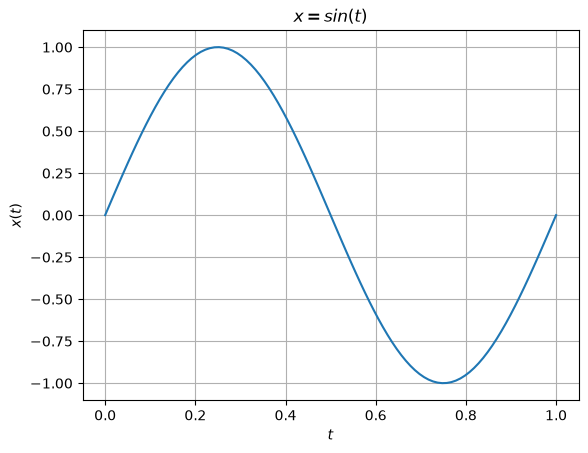

In [48]:
plt.plot(t, x);
plt.xlabel('$t$');
plt.ylabel('$x(t)$');
plt.title('$x = sin(t)$');
plt.grid();

In [49]:
xx = x.reshape(-1, 1) * x.reshape(1, -1)
xx.shape, xx.dtype, xx.min(), xx.max()

((100, 100),
 dtype('float64'),
 np.float64(-0.9997482711915926),
 np.float64(0.9997482711915926))

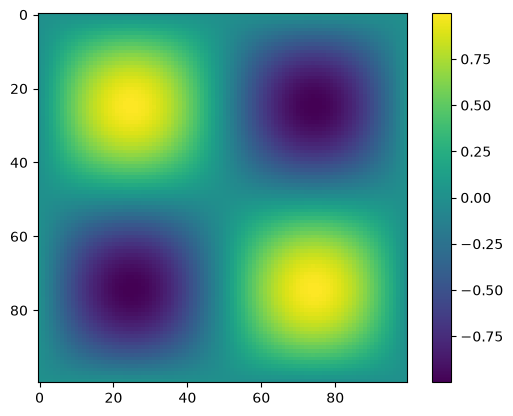

In [50]:
plt.imshow(xx);
plt.colorbar();

In [51]:
tx, ty = np.meshgrid(t, t)
print(tx.shape, tx.dtype, tx.min(), tx.max())
print(ty.shape, ty.dtype, ty.min(), ty.max())

(100, 100) float64 0.0 1.0
(100, 100) float64 0.0 1.0


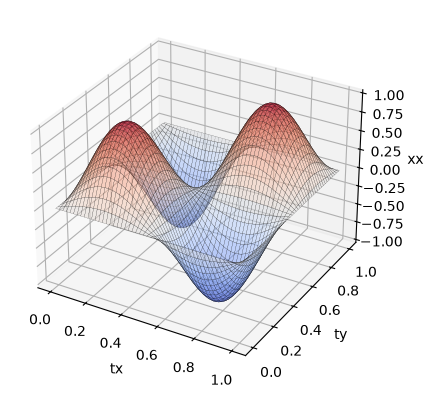

In [52]:
ax = plt.figure().add_subplot(projection='3d')
ax.plot_surface(tx, ty, xx, cmap='coolwarm', ec='k', lw=0.1, alpha=0.5);
ax.set_xlabel('tx');
ax.set_ylabel('ty');
ax.set_zlabel('xx');
# ax.view_init(elev=30, azim=120, roll=0);

# Scikit-image

- scikit-image je sbírka algoritmů pro zpracování obrazu.
- Zahrnuje algoritmy pro segmentaci, geometrické transformace, převody mezi barevnými prostory, analýzu, filtrování, morfologické operace, detekci příznaků (features) a další.
- Je navržena tak, aby dobře spolupracovala s vědeckými knihovnami NumPy a SciPy.
- Funkčně je obdobou Image Processing Toolboxu v Matlabu.

<figure class="image">
  <img src="../figures/skimage_logo.png" alt="" style="height: 1.6in"/>
</figure>

https://scikit-image.org/

In [53]:
import skimage

In [54]:
rgb = skimage.io.imread('../data/kitten.jpg')
type(rgb), rgb.shape, rgb.dtype, rgb.min(), rgb.max()

(numpy.ndarray, (3396, 3396, 3), dtype('uint8'), np.uint8(0), np.uint8(255))

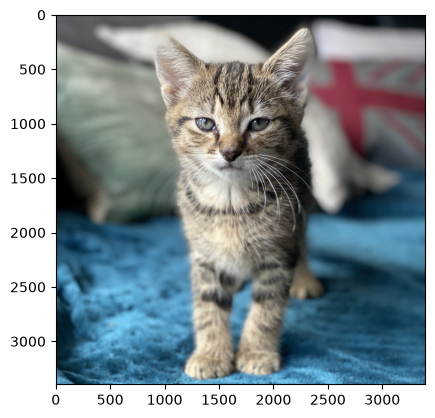

In [55]:
plt.imshow(rgb);

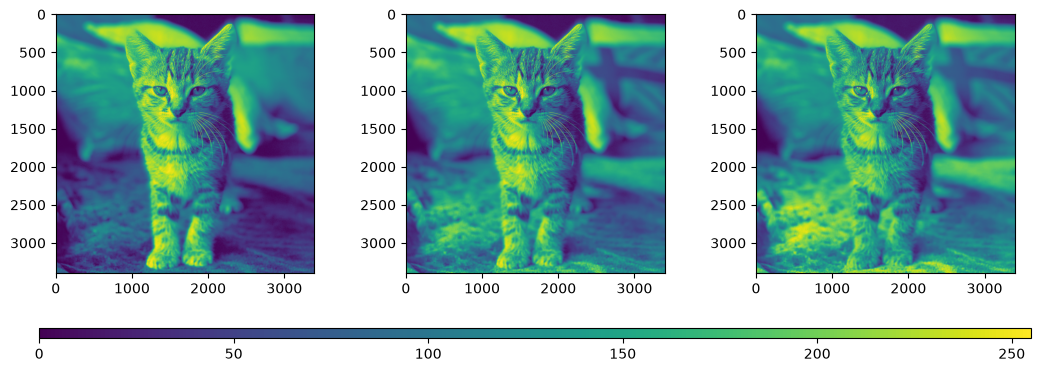

In [56]:
fig, axes = plt.subplots(1, 3, figsize=plt.figaspect(0.375))
im = axes[0].imshow(rgb[:, :, 0])  # R
im = axes[1].imshow(rgb[:, :, 1])  # G
im = axes[2].imshow(rgb[:, :, 2]);  # B
fig.colorbar(im, ax=axes, orientation='horizontal', aspect=100);

In [57]:
gray = skimage.color.rgb2gray(rgb)
gray.shape, gray.dtype, gray.min(), gray.max()

((3396, 3396), dtype('float64'), np.float64(0.0), np.float64(1.0))

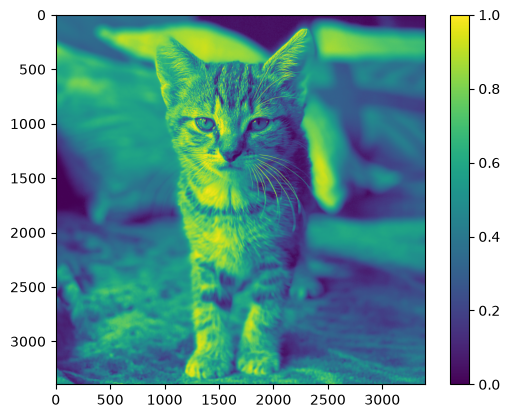

In [58]:
plt.imshow(gray)
plt.colorbar();

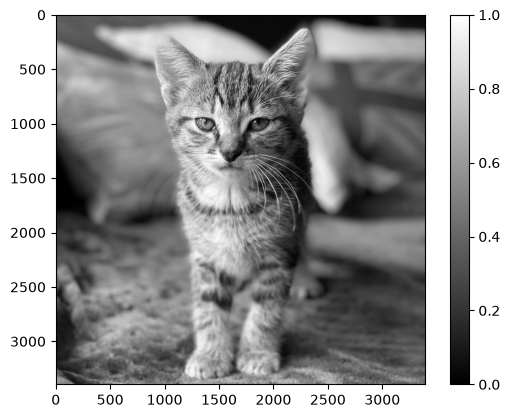

In [59]:
plt.imshow(gray, cmap='gray', vmin=0, vmax=1)
plt.colorbar();

## Obrázky typu uint8 vs. float

In [60]:
rgb / 255.

array([[[0.4       , 0.45490196, 0.45882353],
        [0.40392157, 0.44705882, 0.45490196],
        [0.38823529, 0.42352941, 0.44313725],
        ...,
        [0.14509804, 0.19607843, 0.22745098],
        [0.19215686, 0.25098039, 0.27843137],
        [0.18823529, 0.25490196, 0.28235294]],

       [[0.39215686, 0.44705882, 0.45098039],
        [0.39607843, 0.43921569, 0.44705882],
        [0.38823529, 0.41568627, 0.43921569],
        ...,
        [0.14117647, 0.19215686, 0.22352941],
        [0.18823529, 0.24705882, 0.2745098 ],
        [0.19215686, 0.25098039, 0.27843137]],

       [[0.38431373, 0.42745098, 0.43529412],
        [0.38431373, 0.42352941, 0.43137255],
        [0.37254902, 0.40392157, 0.41568627],
        ...,
        [0.12941176, 0.17254902, 0.19607843],
        [0.16078431, 0.21176471, 0.23529412],
        [0.15686275, 0.21568627, 0.23529412]],

       ...,

       [[0.4745098 , 0.55686275, 0.63137255],
        [0.4745098 , 0.55686275, 0.63921569],
        [0.47058824, 0

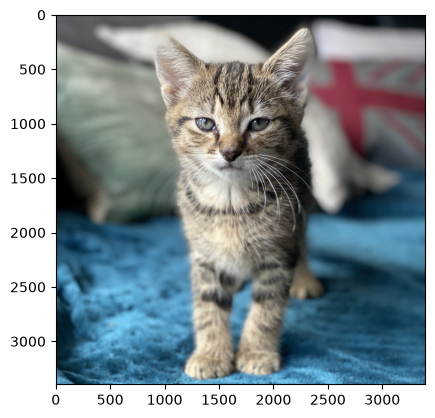

In [61]:
plt.imshow(rgb / 255.);

`plt.imshow` se dívá i na `dtype` svého argumentu a podle něj se rozhoduje:
- obrázky typu `uint8` vykreslí tak, že 0 odpovídá minimu a 255 maximu,
- obrázky typu `float32` nebo `float` vykreslí tak, že 0 odpovídá minimu a 1 maximu.

Jakákoli hodnota typu `float` větší než 1 se vykreslí jako bílá, takže pokud obrázek nevydělíme 255, dostaneme téměř bílý výstup:

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].


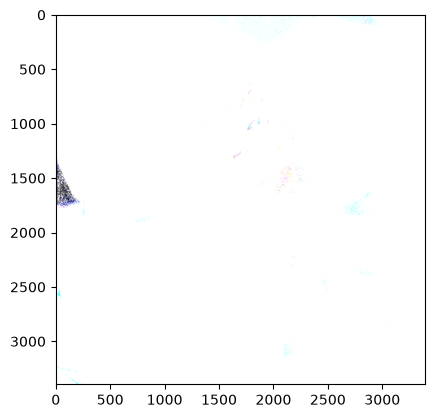

In [62]:
plt.imshow(rgb.astype(float));

Správný způsob, jak v scikit-image převádět datový typ obrázků, je použít funkce `skimage.util.img_as_xxx` takto (obdoba funkcí `im2double`, `im2uint8` apod. v Matlabu):

In [63]:
rgb_f = skimage.util.img_as_float(rgb)  # convert to float dtype (0..1)
rgb_b = skimage.util.img_as_ubyte(rgb_f)  # convert back to unsigned byte (0..255)

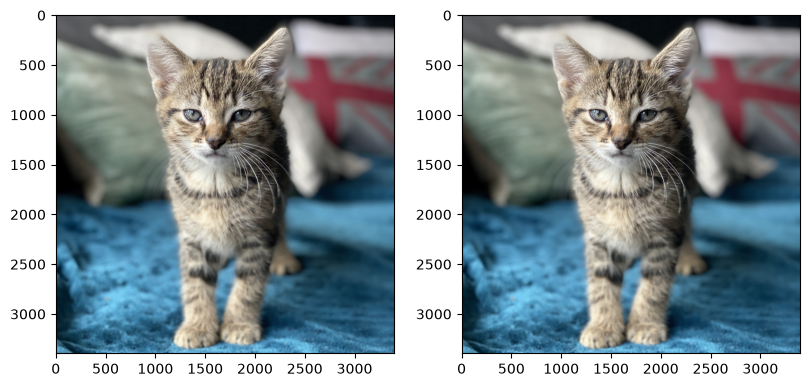

In [64]:
fig, axes = plt.subplots(1, 2, figsize=plt.figaspect(0.5))
axes[0].imshow(rgb_f)
axes[1].imshow(rgb_b);

## Pozor na přetečení (overflow) u celočíselných typů

Na rozdíl od Matlabu, kde aritmetické operace s celočíselnými typy **saturují** (výsledek se ořeže na rozsah datového typu, např. `uint8(250) + uint8(10)` dá v Matlabu `255`), NumPy celočíselné typy při přetečení **obtáčí (wrap-around)** bez jakéhokoli varování nebo chyby:

In [65]:
a = np.array([250], dtype=np.uint8)
b = np.array([10], dtype=np.uint8)
a + b

array([4], dtype=uint8)

Výsledek `4` vznikl jako `(250 + 10) mod 256` - žádná výjimka ani varování se nevypíše. Při práci s obrázky (typicky uloženými jako `uint8`) je to velmi častá příčina chyb, např. při odečítání dvou obrázků nebo výpočtu rozdílového snímku. Řešením je před aritmetickými operacemi převést obrázek na `float` (např. `skimage.util.img_as_float` nebo `.astype(float)`) a výsledek případně až zpětně převést na `uint8`.

# OpenCV

- OpenCV (Open Source Computer Vision) je knihovna funkcí určená především pro počítačové vidění v reálném čase.
- Zahrnuje
  - nástroje pro 2D a 3D příznaky (features),
  - rozpoznávání obličejů,
  - rozpoznávání gest,
  - interakci člověka s počítačem (HCI),
  - mobilní robotiku,
  - analýzu pohybu,
  - detekci objektů,
  - segmentaci a rozpoznávání,
  - stereo vidění,
  - structure from motion,
  - sledování pohybu ve videu,
  - a další.
- Obsahuje také algoritmy strojového učení, např. Boosting, rozhodovací stromy, support vector machine (SVM), hluboké neuronové sítě a další.

<figure class="image">
  <img src="../figures/opencv_logo.webp" alt="" style="height: 1.6in"/>
</figure>

https://opencv.org/

In [66]:
import cv2 as cv

In [67]:
bgr = cv.imread('../data/kitten.jpg')
type(bgr), bgr.shape, bgr.dtype

(numpy.ndarray, (3396, 3396, 3), dtype('uint8'))

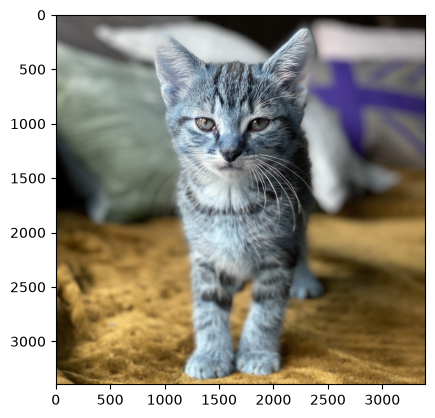

In [68]:
plt.imshow(bgr);

`plt.imshow` se nejprve podívá na vstupní argument (v našem případě `bgr`) a pokud je to `ndarray` s tvarem `(výška, šířka, 3)`, vykreslí ho jako RGB obrázek - tedy očekává, že `bgr[:, :, 0]` je červený kanál. To ale v případě obrázku načteného funkcí `cv.imread` neplatí (OpenCV načítá kanály v pořadí BGR). Proto jsou na obrázku výše barvy prohozené.

Abychom to opravili, po načtení obrázku funkcí `cv.imread` obrátíme pořadí kanálů pomocí NumPy indexování `[..., ::-1]`.

In [69]:
rgb_cv = cv.imread('../data/kitten.jpg')[..., ::-1]
type(rgb_cv), rgb_cv.shape, rgb_cv.dtype

(numpy.ndarray, (3396, 3396, 3), dtype('uint8'))

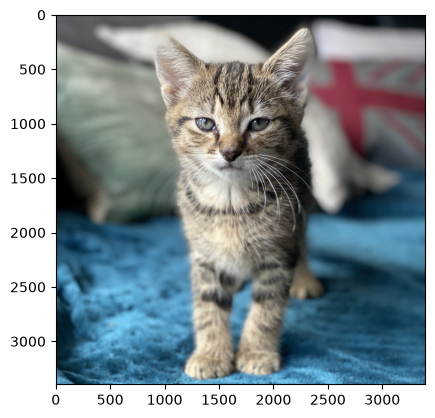

In [70]:
plt.imshow(rgb_cv);

In [71]:
np.abs(rgb - rgb_cv).sum()  # stejný obrázek jako ze skimage

np.uint64(0)

## Shrnutí

| Knihovna | Účel | Obdoba v Matlabu |
|---|---|---|
| NumPy | vícerozměrná pole, lineární algebra, vektorizace | jádro Matlabu (matice, `:`, broadcasting) |
| Matplotlib | 2D/3D grafy a vykreslování obrázků | `plot`, `imshow`, `surf`, `mesh` |
| Seaborn | statistické grafy nad Matplotlib | - |
| scikit-image | algoritmy pro zpracování obrazu, pracuje v RGB a `float` v rozsahu `[0, 1]` | Image Processing Toolbox |
| OpenCV | počítačové vidění v reálném čase, pracuje v BGR a `uint8` | Computer Vision Toolbox |

**Co si z této lekce odnést především:**
- indexování od 0 a `stop` nezahrnuté ve výřezech,
- výřezy vrací view, ne kopii,
- celočíselná aritmetika (`uint8`) v NumPy přetéká (wrap-around), nesaturuje jako v Matlabu,
- scikit-image očekává RGB a obrázky typu `float` v rozsahu `[0, 1]`, OpenCV načítá obrázky jako BGR a `uint8`.

Dalšími knihovnami, se kterými se v kurzu ještě setkáme, jsou např. Pillow (PIL) pro základní práci s obrázky a torchvision/albumentations u konvolučních neuronových sítí.